In [ ]:
import requests
import os
import random
from typing import Annotated
from typing_extensions import TypedDict
from IPython.display import Image, display
import gradio as gr
from langchain_openai import ChatOpenAI
from langchain_community.tools import GoogleSerperRun
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages

In [ ]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)


In [8]:
from dotenv import load_dotenv
load_dotenv()
api_key = os.getenv("api_key")
print(f"api_key:{api_key[:8]}")

api_key:gsk_dLeR


In [12]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    api_key=api_key
)

In [17]:
search = GoogleSerperRun(api_wrapper=GoogleSerperAPIWrapper())

@tool
def send_push_notification(text: str) -> str:
    """Send a short push notification to the user's phone."""
    requests.post(
        "https://api.pushover.net/1/messages.json",
        data={"token": os.getenv("PUSHOVER_TOKEN"), "user": os.getenv("PUSHOVER_USER"), "message": text},
    )
    return "Notification sent"

tools = [search, send_push_notification]
llm_with_tools = llm.bind_tools(tools)

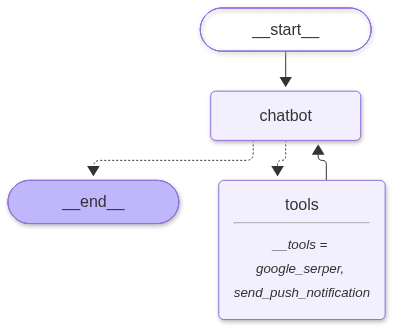

In [18]:
def chatbot_node(state: State) -> dict:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
builder.add_edge("tools", "chatbot")

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

